**CARGAMOS EL DATASET**

In [1]:
from google.colab import files

uploaded = files.upload()

Saving EEGIS - Electroencephalogram Imagined Speech dataset.zip to EEGIS - Electroencephalogram Imagined Speech dataset.zip


In [2]:
import os

print(os.listdir("/content"))

['.config', 'EEGIS - Electroencephalogram Imagined Speech dataset.zip', 'sample_data']


**DESCOMPRIMIMOS EL DATASET**

In [3]:
import zipfile
from pathlib import Path

zip_path = Path("/content/EEGIS - Electroencephalogram Imagined Speech dataset.zip")
extract_path = Path("/content/EEGIS_dataset")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset descomprimido en:")
print(extract_path)

Dataset descomprimido en:
/content/EEGIS_dataset


In [4]:
import os

print(os.listdir("/content/EEGIS_dataset"))

['EEGIS - Electroencephalogram Imagined Speech dataset']


**OBSERVAMOS LA ESTRUCTURA INTERNA**

In [5]:
base_path = "/content/EEGIS_dataset/EEGIS - Electroencephalogram Imagined Speech dataset"

print(os.listdir(base_path))

['alpha', 'raw', 'delta', 'gamma', 'beta', 'readme.txt', 'theta']


**REVISAMOS LAS CLASES EN 'raw'**

In [6]:
raw_path = os.path.join(base_path, "raw")

print(os.listdir(raw_path))

['class_4', 'class_6', 'class_8', 'class_0', 'class_3', 'class_5', 'desktop.ini', 'class_7', 'class_2', 'class_1']


**CONTAMOS LOS ARCHIVOS**

In [7]:
import os
import pandas as pd

# Nombres de las nueve clases
class_names = [
    "Reposo",
    "Ayuda",
    "Baño",
    "Dolor",
    "Gracias",
    "Hambre",
    "No",
    "Sed",
    "Sí"
]

# Crear el inventario de archivos
registros = []

for class_id in range(9):

    carpeta = os.path.join(
        raw_path,
        f"class_{class_id}"
    )

    archivos = sorted([
        archivo for archivo in os.listdir(carpeta)
        if archivo.endswith(".csv")
    ])

    for archivo in archivos:

        registros.append({
            "filepath": os.path.join(carpeta, archivo),
            "class_id": class_id,
            "class_name": class_names[class_id]
        })

# Crear DataFrame
df_eeg = pd.DataFrame(registros)

# Calcular distribución de clases
distribucion = (
    df_eeg.groupby(["class_id", "class_name"])
    .size()
    .reset_index(name="Cantidad")
)

distribucion["Porcentaje"] = (
    distribucion["Cantidad"] / len(df_eeg) * 100
)

# Mostrar resultados
display(distribucion.round(2))

print("\nTotal de secuencias EEG:", len(df_eeg))

,class_id,class_name,Cantidad,Porcentaje
0,0,Reposo,456,11.28
1,1,Ayuda,504,12.46
2,2,Baño,372,9.20
3,3,Dolor,492,12.17
4,4,Gracias,444,10.98
5,5,Hambre,444,10.98
6,6,No,480,11.87
7,7,Sed,408,10.09
8,8,Sí,444,10.98



Total de secuencias EEG: 4044


**ABRIMOS UN CSV DE EJEMPLO**

In [8]:
import pandas as pd

# Seleccionar un archivo de ejemplo del inventario completo
sample_file = df_eeg["filepath"].iloc[0]

# Leer el archivo CSV
df_sample = pd.read_csv(sample_file)

print("Archivo:")
print(sample_file)

print("\nShape:")
print(df_sample.shape)

print("\nColumnas:")
print(df_sample.columns.tolist())

print("\nPrimeras filas:")
display(df_sample.head())

Archivo:
/content/EEGIS_dataset/EEGIS - Electroencephalogram Imagined Speech dataset/raw/class_0/0.csv

Shape:
(128, 15)

Columnas:
['Unnamed: 0', 'AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1', 'O2', 'P8', 'T8', 'FC6', 'F4', 'F8', 'AF4']

Primeras filas:


,Unnamed: 0,AF3,F7,F3,FC5,T7,P7,O1,O2,P8,T8,FC6,F4,F8,AF4
0,0,4066.153809,4115.384766,4200.512695,4117.436035,4201.538574,4182.051270,4163.077148,4106.666504,4154.358887,4168.205078,4128.205078,4169.230957,4106.666504,4120.000000
1,1,4078.461426,4129.743652,4200.000000,4122.051270,4201.025879,4176.922852,4160.000000,4105.641113,4157.948730,4170.769043,4136.922852,4173.333496,4106.666504,4126.153809
2,2,4076.410156,4134.871582,4200.512695,4118.974121,4202.051270,4172.820313,4154.871582,4104.615234,4157.436035,4173.333496,4140.512695,4182.563965,4114.358887,4136.410156
3,3,4088.718018,4134.871582,4202.051270,4127.179688,4204.102539,4174.871582,4155.897461,4100.512695,4153.333496,4173.333496,4145.128418,4194.871582,4125.641113,4145.641113
4,4,4102.051270,4135.897461,4196.922852,4136.922852,4203.589844,4172.820313,4147.692383,4091.281982,4150.256348,4171.282227,4155.897461,4201.538574,4134.871582,4156.922852


**ELIMINAMOS LA COLUMNA DEL ÍNDICE Y REVISAMOS LOS DATOS**

In [9]:
import numpy as np

# Eliminar la columna de índice
df_clean = df_sample.drop(
    columns=["Unnamed: 0"]
)

print("Shape después de eliminar el índice:")
print(df_clean.shape)

print("\nColumnas:")
print(df_clean.columns.tolist())

print("\nValores faltantes:")
print(df_clean.isna().sum().sum())

print("\nTodos los valores son finitos:")
print(np.isfinite(df_clean.to_numpy()).all())

print("\nTipos de datos:")
print(df_clean.dtypes)

display(df_clean.head())

Shape después de eliminar el índice:
(128, 14)

Columnas:
['AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1', 'O2', 'P8', 'T8', 'FC6', 'F4', 'F8', 'AF4']

Valores faltantes:
0

Todos los valores son finitos:
True

Tipos de datos:
AF3    float64
F7     float64
F3     float64
FC5    float64
T7     float64
P7     float64
O1     float64
O2     float64
P8     float64
T8     float64
FC6    float64
F4     float64
F8     float64
AF4    float64
dtype: object


,AF3,F7,F3,FC5,T7,P7,O1,O2,P8,T8,FC6,F4,F8,AF4
0,4066.153809,4115.384766,4200.512695,4117.436035,4201.538574,4182.051270,4163.077148,4106.666504,4154.358887,4168.205078,4128.205078,4169.230957,4106.666504,4120.000000
1,4078.461426,4129.743652,4200.000000,4122.051270,4201.025879,4176.922852,4160.000000,4105.641113,4157.948730,4170.769043,4136.922852,4173.333496,4106.666504,4126.153809
2,4076.410156,4134.871582,4200.512695,4118.974121,4202.051270,4172.820313,4154.871582,4104.615234,4157.436035,4173.333496,4140.512695,4182.563965,4114.358887,4136.410156
3,4088.718018,4134.871582,4202.051270,4127.179688,4204.102539,4174.871582,4155.897461,4100.512695,4153.333496,4173.333496,4145.128418,4194.871582,4125.641113,4145.641113
4,4102.051270,4135.897461,4196.922852,4136.922852,4203.589844,4172.820313,4147.692383,4091.281982,4150.256348,4171.282227,4155.897461,4201.538574,4134.871582,4156.922852


**CARGAMOS LOS CSV**

In [10]:
import numpy as np
import pandas as pd

# Orden de los 14 canales EEG
eeg_channels = [
    "AF3", "F7", "F3", "FC5", "T7", "P7", "O1",
    "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"
]

# Listas para almacenar las secuencias y sus etiquetas
X = []
y = []

# Recorrer el inventario de las nueve clases
for _, fila in df_eeg.iterrows():

    # Leer el archivo CSV
    df = pd.read_csv(fila["filepath"])

    # Seleccionar únicamente los 14 canales EEG
    signal = df[eeg_channels].to_numpy(dtype=np.float32)

    # Verificar que cada secuencia tenga 128 muestras y 14 canales
    if signal.shape != (128, 14):
        raise ValueError(
            f"Dimensiones incorrectas en {fila['filepath']}: "
            f"{signal.shape}"
        )

    # Verificar que no existan valores faltantes o infinitos
    if not np.isfinite(signal).all():
        raise ValueError(
            f"Se encontraron valores no válidos en {fila['filepath']}"
        )

    # Guardar la secuencia y su etiqueta
    X.append(signal)
    y.append(int(fila["class_id"]))

# Convertir las listas en arreglos NumPy
X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int32)

# Mostrar las dimensiones finales
print("Shape de X:", X.shape)
print("Shape de y:", y.shape)

Shape de X: (4044, 128, 14)
Shape de y: (4044,)


**COMPROBAR LAS ETIQUETAS**

In [11]:
# Obtener las etiquetas y su cantidad de muestras
unique, counts = np.unique(y, return_counts=True)

print("Distribución de clases:\n")

for label, count in zip(unique, counts):
    print(f"Clase {label} ({class_names[label]}): {count} secuencias")

print("\nEtiquetas presentes:", unique)
print("Total de secuencias:", counts.sum())

Distribución de clases:

Clase 0 (Reposo): 456 secuencias
Clase 1 (Ayuda): 504 secuencias
Clase 2 (Baño): 372 secuencias
Clase 3 (Dolor): 492 secuencias
Clase 4 (Gracias): 444 secuencias
Clase 5 (Hambre): 444 secuencias
Clase 6 (No): 480 secuencias
Clase 7 (Sed): 408 secuencias
Clase 8 (Sí): 444 secuencias

Etiquetas presentes: [0 1 2 3 4 5 6 7 8]
Total de secuencias: 4044


**HACEMOS EL SPLIT DE LOS DATOS**

In [12]:
from sklearn.model_selection import train_test_split
import numpy as np

# Primera división: 80% entrenamiento y 20% temporal
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Segunda división: 10% validación y 10% prueba
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Mostrar las dimensiones de los conjuntos
print("Entrenamiento:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nValidación:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nPrueba:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# Verificar que las nueve clases estén presentes
print("\nClases en entrenamiento:", np.unique(y_train))
print("Clases en validación:", np.unique(y_val))
print("Clases en prueba:", np.unique(y_test))

Entrenamiento:
X_train: (3235, 128, 14)
y_train: (3235,)

Validación:
X_val: (404, 128, 14)
y_val: (404,)

Prueba:
X_test: (405, 128, 14)
y_test: (405,)

Clases en entrenamiento: [0 1 2 3 4 5 6 7 8]
Clases en validación: [0 1 2 3 4 5 6 7 8]
Clases en prueba: [0 1 2 3 4 5 6 7 8]


**VERIFICAMOS EL BALANCE DE CLASES**

In [13]:
def mostrar_distribucion(nombre, etiquetas):
    valores, conteos = np.unique(
        etiquetas,
        return_counts=True
    )

    print(f"\n{nombre}")

    for valor, conteo in zip(valores, conteos):
        clase = class_names[valor]
        porcentaje = conteo / len(etiquetas) * 100

        print(
            f"{clase}: {conteo} "
            f"({porcentaje:.2f}%)"
        )


mostrar_distribucion("TRAIN", y_train)
mostrar_distribucion("VALIDATION", y_val)
mostrar_distribucion("TEST", y_test)


TRAIN
Reposo: 365 (11.28%)
Ayuda: 403 (12.46%)
Baño: 298 (9.21%)
Dolor: 394 (12.18%)
Gracias: 355 (10.97%)
Hambre: 355 (10.97%)
No: 384 (11.87%)
Sed: 326 (10.08%)
Sí: 355 (10.97%)

VALIDATION
Reposo: 45 (11.14%)
Ayuda: 50 (12.38%)
Baño: 37 (9.16%)
Dolor: 49 (12.13%)
Gracias: 45 (11.14%)
Hambre: 45 (11.14%)
No: 48 (11.88%)
Sed: 41 (10.15%)
Sí: 44 (10.89%)

TEST
Reposo: 46 (11.36%)
Ayuda: 51 (12.59%)
Baño: 37 (9.14%)
Dolor: 49 (12.10%)
Gracias: 44 (10.86%)
Hambre: 44 (10.86%)
No: 48 (11.85%)
Sed: 41 (10.12%)
Sí: 45 (11.11%)


**CALCULAMOS MEDIA Y DESVIACIÓN ESTANDAR DE TRAINING**

In [14]:
# Calcular la media y desviación estándar de cada canal EEG
# utilizando únicamente el conjunto de entrenamiento
train_mean = X_train.astype(np.float64).mean(axis=(0, 1))
train_std = X_train.astype(np.float64).std(axis=(0, 1))

# Evitar divisiones entre cero si algún canal tiene desviación nula
train_std = np.where(train_std == 0, 1.0, train_std)

# Mostrar resultados
print("Shape de la media:", train_mean.shape)
print("Shape de la desviación estándar:", train_std.shape)

print("\nMedia por canal:")
print(train_mean)

print("\nDesviación estándar por canal:")
print(train_std)

Shape de la media: (14,)
Shape de la desviación estándar: (14,)

Media por canal:
[4206.16294285 4206.34805396 4205.67918201 4206.78565414 4206.06793091
 4206.37217596 4206.67920712 4206.81858201 4207.18166682 4206.81763856
 4206.28282395 4210.17061731 4205.97197242 4206.00090199]

Desviación estándar por canal:
[ 37.69606631  34.29189984  30.70136602  33.78745009  25.97519975
  63.61895031  83.39081645  35.57491691  37.93798526  28.30542479
  38.02591372  33.0149217  172.85298927  48.07059612]


**ESTANDARIZAMOS TRAINING, VALIDATION, Y TESTING**

In [15]:
# Estandarizar los tres conjuntos utilizando las estadísticas de entrenamiento
X_train_norm = (
    (X_train.astype(np.float64) - train_mean) / train_std
).astype(np.float32)

X_val_norm = (
    (X_val.astype(np.float64) - train_mean) / train_std
).astype(np.float32)

X_test_norm = (
    (X_test.astype(np.float64) - train_mean) / train_std
).astype(np.float32)

# Verificar las dimensiones
print("X_train_norm:", X_train_norm.shape)
print("X_val_norm:", X_val_norm.shape)
print("X_test_norm:", X_test_norm.shape)

# Verificar la estandarización del conjunto de entrenamiento
print("\nMedia global de entrenamiento:", X_train_norm.mean())
print("Desviación estándar global de entrenamiento:", X_train_norm.std())

# Verificar que no existan valores no válidos
print("\n¿Todos los valores son finitos?")
print("Train:", np.isfinite(X_train_norm).all())
print("Validation:", np.isfinite(X_val_norm).all())
print("Test:", np.isfinite(X_test_norm).all())

X_train_norm: (3235, 128, 14)
X_val_norm: (404, 128, 14)
X_test_norm: (405, 128, 14)

Media global de entrenamiento: 0.0
Desviación estándar global de entrenamiento: 1.0

¿Todos los valores son finitos?
Train: True
Validation: True
Test: True


**VERIFICAMOS LA NORMALIZACIÓN**

In [ ]:
print("Media global de Train normalizado:")
print(X_train_norm.mean())

print("\nDesviación estándar global de Train normalizado:")
print(X_train_norm.std())

print("\nTodos los valores son finitos:")
print(
    np.isfinite(X_train_norm).all(),
    np.isfinite(X_val_norm).all(),
    np.isfinite(X_test_norm).all()
)

Media global de Train normalizado:
1.6635079e-09

Desviación estándar global de Train normalizado:
1.0000002

Todos los valores son finitos:
True True True


**COMPROBAMOS TENSORFLOW Y GPU**

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPUs disponibles:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPUs disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**CREAMOS LA LSTM BASELINE**

In [ ]:
# Crear la LSTM baseline para clasificación de nueve clases
model_rnn = tf.keras.Sequential([

    # Entrada: 128 muestras temporales y 14 canales EEG
    tf.keras.layers.Input(shape=(128, 14)),

    # Capa recurrente
    tf.keras.layers.LSTM(64),

    # Regularización
    tf.keras.layers.Dropout(0.30),

    # Capa densa
    tf.keras.layers.Dense(32, activation="relu"),

    # Salida: una probabilidad para cada una de las nueve clases
    tf.keras.layers.Dense(9, activation="softmax")
])

**OBSERVAMOS LA ARQUITECTURA**

In [ ]:
model_rnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 9)              │           297 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,601 (88.29 KB)

 Trainable params: 22,601 (88.29 KB)

 Non-trainable params: 0 (0.00 B)

**COMPILAMOS LA LSTM**

In [ ]:

model_rnn.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("LSTM multiclase compilada correctamente.")

LSTM multiclase compilada correctamente.


**PREPARAMOS LOS CALLBACKS Y ENTRENAMOS**

In [ ]:
early_stopping_rnn = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr_rnn = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

EPOCHS = 30

history_rnn = model_rnn.fit(
    X_train_norm,
    y_train,
    validation_data=(X_val_norm, y_val),
    epochs=EPOCHS,
    batch_size=32,
    callbacks=[
        early_stopping_rnn,
        reduce_lr_rnn
    ]
)

Epoch 1/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - accuracy: 0.1172 - loss: 2.2067 - val_accuracy: 0.1337 - val_loss: 2.1893 - learning_rate: 0.0010
Epoch 2/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.1388 - loss: 2.1838 - val_accuracy: 0.1535 - val_loss: 2.1866 - learning_rate: 0.0010
Epoch 3/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1573 - loss: 2.1710 - val_accuracy: 0.1634 - val_loss: 2.1864 - learning_rate: 0.0010
Epoch 4/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1669 - loss: 2.1546 - val_accuracy: 0.1683 - val_loss: 2.1831 - learning_rate: 0.0010
Epoch 5/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1808 - loss: 2.1452 - val_accuracy: 0.1262 - val_loss: 2.1857 - learning_rate: 0.0010
Epoch 6/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1873 - loss: 2.1323 - val_accuracy: 0.1312 - val_loss: 2.1830 - learning_rate: 0.0010
Epoch 7/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1978 - loss: 2.

In [ ]:
import numpy as np

# Época con la menor pérdida de validación
best_epoch_rnn = np.argmin(history_rnn.history["val_loss"]) + 1

best_val_loss_rnn = history_rnn.history["val_loss"][best_epoch_rnn - 1]
best_val_accuracy_rnn = history_rnn.history["val_accuracy"][best_epoch_rnn - 1]

print("Mejor época:", best_epoch_rnn)
print(f"Validation Loss: {best_val_loss_rnn:.4f}")
print(f"Validation Accuracy: {best_val_accuracy_rnn:.4f}")



Mejor época: 7
Validation Loss: 2.1807
Validation Accuracy: 0.1411


**GRÁFICA DE ACCURACY**

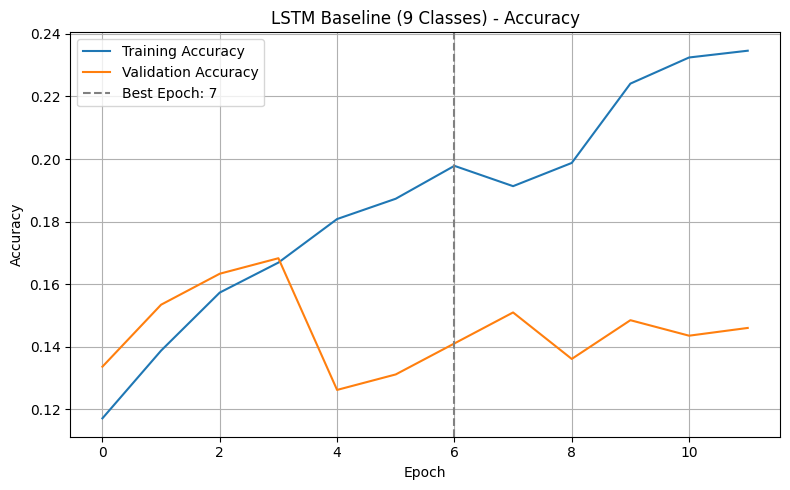

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history_rnn.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_rnn.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.axvline(
    best_epoch_rnn - 1,
    color="gray",
    linestyle="--",
    label=f"Best Epoch: {best_epoch_rnn}"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Baseline (9 Classes) - Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "/content/rnn_9classes_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**GRÁFICA DE LOSS**

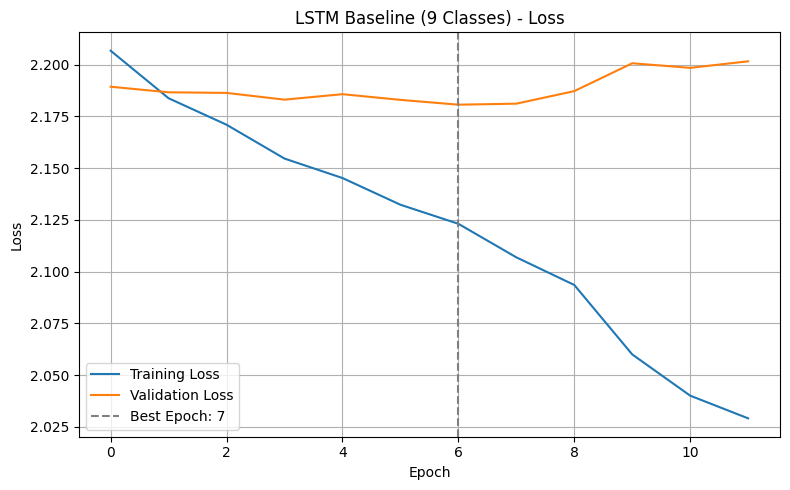

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_rnn.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_rnn.history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    best_epoch_rnn - 1,
    color="gray",
    linestyle="--",
    label=f"Best Epoch: {best_epoch_rnn}"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Baseline (9 Classes) - Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "/content/rnn_9classes_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**EVALUAMOS LA LSTM CON EL CONJUNTO DE TESTING**

In [ ]:
# Evaluar la LSTM de nueve clases con el conjunto de prueba
test_loss_rnn, test_accuracy_rnn = model_rnn.evaluate(
    X_test_norm,
    y_test,
    verbose=1
)

print("\nLSTM Baseline (9 Classes) - Test Results")
print(f"Test Loss: {test_loss_rnn:.4f}")
print(f"Test Accuracy: {test_accuracy_rnn:.4f}")
print(f"Test Accuracy (%): {test_accuracy_rnn * 100:.2f}%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1333 - loss: 2.1790

LSTM Baseline (9 Classes) - Test Results
Test Loss: 2.1790
Test Accuracy: 0.1333
Test Accuracy (%): 13.33%


**OBTENEMOS LAS PREDICCIONES Y MÉTRICAS DE CLASIFICACIÓN**

In [ ]:
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Obtener las probabilidades de las nueve clases
y_prob_rnn = model_rnn.predict(
    X_test_norm,
    verbose=0
)

# Seleccionar la clase con mayor probabilidad
y_pred_rnn = np.argmax(y_prob_rnn, axis=1)

# Calcular las métricas
accuracy_rnn = accuracy_score(y_test, y_pred_rnn)

macro_f1_rnn = f1_score(
    y_test,
    y_pred_rnn,
    average="macro",
    zero_division=0
)

# Matriz de confusión
cm_rnn = confusion_matrix(
    y_test,
    y_pred_rnn,
    labels=np.arange(9)
)

# Mostrar los resultados
print("LSTM Baseline (9 Classes) - Classification Results")

print(f"\nTest Accuracy: {accuracy_rnn:.4f}")
print(f"Macro F1: {macro_f1_rnn:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_rnn,
        labels=np.arange(9),
        target_names=class_names,
        zero_division=0
    )
)

print("\nDistribución de predicciones:")

for class_id, class_name in enumerate(class_names):
    cantidad = np.sum(y_pred_rnn == class_id)
    print(f"{class_name}: {cantidad}")

LSTM Baseline (9 Classes) - Classification Results

Test Accuracy: 0.1333
Macro F1: 0.1144

Classification Report:
              precision    recall  f1-score   support

      Reposo       0.15      0.20      0.17        46
       Ayuda       0.14      0.18      0.16        51
        Baño       0.06      0.03      0.04        37
       Dolor       0.20      0.14      0.17        49
     Gracias       0.09      0.05      0.06        44
      Hambre       0.11      0.07      0.08        44
          No       0.16      0.38      0.23        48
         Sed       0.12      0.05      0.07        41
          Sí       0.06      0.07      0.07        45

    accuracy                           0.13       405
   macro avg       0.12      0.13      0.11       405
weighted avg       0.12      0.13      0.12       405


Distribución de predicciones:
Reposo: 62
Ayuda: 65
Baño: 18
Dolor: 35
Gracias: 23
Hambre: 28
No: 110
Sed: 17
Sí: 47


**GRAFICAMOS LA MATRIZ DE CONFUSIÓN**

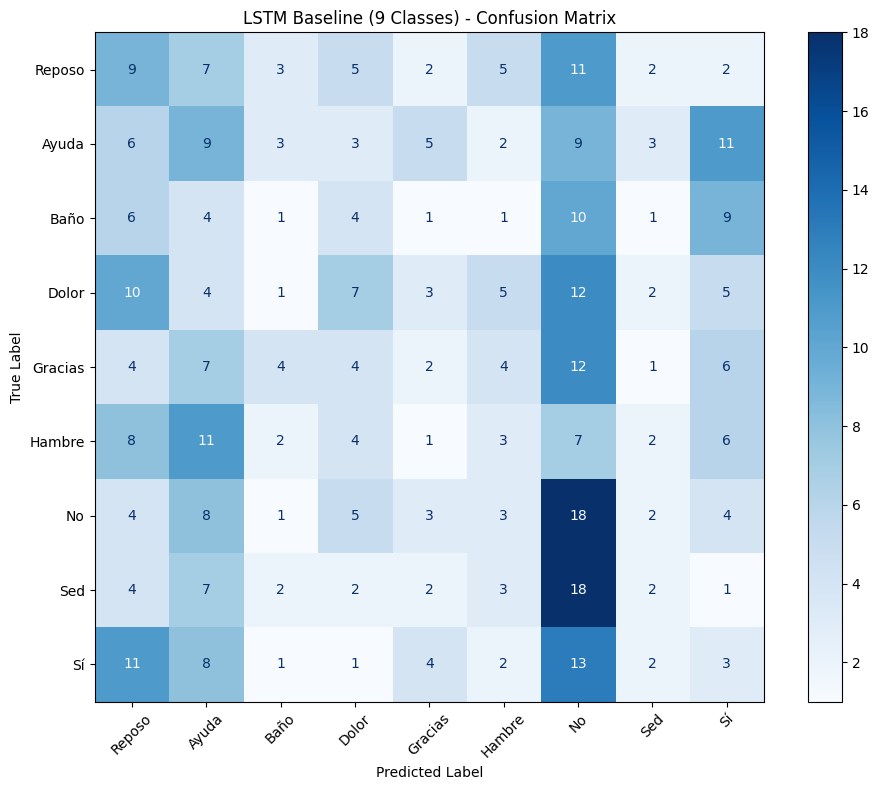

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Crear la matriz de confusión con las nueve clases
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rnn,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True,
    xticks_rotation=45
)

plt.title("LSTM Baseline (9 Classes) - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()

# Guardar la figura para el reporte técnico
plt.savefig(
    "/content/rnn_9classes_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**GUARDAMOS EL MODELO Y LA NORMALIZACIÓN**

In [ ]:
from google.colab import drive
from pathlib import Path
import numpy as np

# Conectar Google Drive
drive.mount("/content/drive")

# Crear una carpeta para guardar el baseline
save_dir = Path("/content/drive/MyDrive/EEGIS_RNN_Baseline")
save_dir.mkdir(parents=True, exist_ok=True)

# Guardar el modelo entrenado
model_rnn.save(save_dir / "lstm_9classes_baseline.keras")

# Guardar las estadísticas utilizadas para normalizar las señales
np.savez(
    save_dir / "normalization_stats.npz",
    train_mean=train_mean,
    train_std=train_std,
    eeg_channels=np.array(eeg_channels),
    class_names=np.array(class_names)
)

print("Modelo y estadísticas guardados en:")
print(save_dir)

Mounted at /content/drive
Modelo y estadísticas guardados en:
/content/drive/MyDrive/EEGIS_RNN_Baseline


**GUARDAMOS LOS RESULTADOS DEL EXPERIMENTO**

In [ ]:
import pandas as pd
import shutil
from pathlib import Path

# Carpeta de Google Drive creada en el paso anterior
save_dir = Path("/content/drive/MyDrive/EEGIS_RNN_Baseline")

# 1. Guardar las métricas principales del baseline
resultados_rnn = pd.DataFrame([{
    "experiment_id": "RNN-B01",
    "model": "LSTM",
    "num_classes": 9,
    "num_sequences": 4044,
    "train_samples": len(y_train),
    "validation_samples": len(y_val),
    "test_samples": len(y_test),
    "lstm_units": 64,
    "dropout": 0.30,
    "batch_size": 32,
    "initial_learning_rate": 0.001,
    "max_epochs": 30,
    "best_epoch": best_epoch_rnn,
    "best_val_loss": best_val_loss_rnn,
    "best_val_accuracy": best_val_accuracy_rnn,
    "test_loss": test_loss_rnn,
    "test_accuracy": accuracy_rnn,
    "macro_f1": macro_f1_rnn
}])

resultados_rnn.to_csv(
    save_dir / "rnn_experiment_log.csv",
    index=False
)

# 2. Guardar las métricas de cada época
pd.DataFrame(history_rnn.history).to_csv(
    save_dir / "rnn_training_history.csv",
    index=False
)

# 3. Copiar las gráficas a Google Drive
graficas = [
    "rnn_9classes_accuracy.png",
    "rnn_9classes_loss.png",
    "rnn_9classes_confusion_matrix.png"
]

for nombre in graficas:
    origen = Path("/content") / nombre

    if origen.exists():
        shutil.copy2(origen, save_dir / nombre)
        print(f"Gráfica guardada: {nombre}")
    else:
        print(f"No se encontró la gráfica: {nombre}")

print("\nResultados del experimento:")
display(resultados_rnn.T)

print("\nArchivos guardados en:")
print(save_dir)

Gráfica guardada: rnn_9classes_accuracy.png
Gráfica guardada: rnn_9classes_loss.png
Gráfica guardada: rnn_9classes_confusion_matrix.png

Resultados del experimento:


,0
experiment_id,RNN-B01
model,LSTM
num_classes,9
num_sequences,4044
train_samples,3235
validation_samples,404
test_samples,405
lstm_units,64
dropout,0.3
batch_size,32



Archivos guardados en:
/content/drive/MyDrive/EEGIS_RNN_Baseline


## RNN-D02 - Gradient Clipping Experiment

In [16]:
import tensorflow as tf
from tensorflow.keras import layers, models

SEED = 42
tf.keras.utils.set_random_seed(SEED)

# ---------------------------------------------------------
# Construir RNN-D02
# Mismo modelo que RNN-B01
# Único cambio: gradient clipping
# ---------------------------------------------------------

model_D02 = models.Sequential([

    layers.Input(
        shape=(128, 14)
    ),

    layers.LSTM(
        64
    ),

    layers.Dropout(
        0.30
    ),

    layers.Dense(
        32,
        activation="relu"
    ),

    layers.Dense(
        9,
        activation="softmax"
    )
])

# ---------------------------------------------------------
# Adam + gradient clipping
# ---------------------------------------------------------

optimizer_D02 = tf.keras.optimizers.Adam(
    learning_rate=0.001,
    clipnorm=1.0
)

model_D02.compile(
    optimizer=optimizer_D02,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("RNN-D02 created successfully.")
print("Gradient clipping: clipnorm = 1.0")
print("Learning rate: 0.001")

model_D02.summary()

RNN-D02 created successfully.
Gradient clipping: clipnorm = 1.0
Learning rate: 0.001


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │           297 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,601 (88.29 KB)

 Trainable params: 22,601 (88.29 KB)

 Non-trainable params: 0 (0.00 B)

## RNN-D02 - Training Callbacks

In [17]:
import os

# ---------------------------------------------------------
# Carpeta para Deliverable 2
# ---------------------------------------------------------

RNN_MODEL_DIR = "/content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models"
os.makedirs(RNN_MODEL_DIR, exist_ok=True)

D02_MODEL_PATH = os.path.join(
    RNN_MODEL_DIR,
    "RNN_D02.keras"
)

# ---------------------------------------------------------
# Configuración
# ---------------------------------------------------------

D02_MAX_EPOCHS = 30

# Guardar automáticamente el mejor modelo
checkpoint_D02 = tf.keras.callbacks.ModelCheckpoint(
    filepath=D02_MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Early stopping
early_stopping_D02 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Reducir learning rate
reduce_lr_D02 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

callbacks_D02 = [
    checkpoint_D02,
    early_stopping_D02,
    reduce_lr_D02
]

print("RNN-D02 callbacks configured.")
print("Maximum epochs:", D02_MAX_EPOCHS)
print("Checkpoint:", D02_MODEL_PATH)

RNN-D02 callbacks configured.
Maximum epochs: 30
Checkpoint: /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D02.keras


## RNN-D02 - Training

In [18]:
history_D02 = model_D02.fit(
    X_train_norm,
    y_train,
    validation_data=(
        X_val_norm,
        y_val
    ),
    epochs=D02_MAX_EPOCHS,
    batch_size=32,
    callbacks=callbacks_D02,
    verbose=1
)

Epoch 1/30
100/102 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.1154 - loss: 2.2123
Epoch 1: val_loss improved from None to 2.19369, saving model to /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D02.keras

Epoch 1: finished saving model to /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D02.keras
102/102 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.1178 - loss: 2.2058 - val_accuracy: 0.1411 - val_loss: 2.1937 - learning_rate: 0.0010
Epoch 2/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.1381 - loss: 2.1818
Epoch 2: val_loss improved from 2.19369 to 2.19016, saving model to /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D02.keras

Epoch 2: finished saving model to /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D02.keras
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.1391 - loss: 2.1821 - val_accuracy: 0.1213 - val_loss: 2.1902 - learning_rate: 0.0010
Epoch 3/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.1475 - 

In [19]:
from sklearn.metrics import f1_score
import numpy as np

# ---------------------------------------------------------
# Evaluación en test
# ---------------------------------------------------------

d02_test_loss, d02_test_accuracy = model_D02.evaluate(
    X_test_norm,
    y_test,
    batch_size=32,
    verbose=1
)

# ---------------------------------------------------------
# Predicciones
# ---------------------------------------------------------

d02_prob = model_D02.predict(
    X_test_norm,
    batch_size=32,
    verbose=1
)

d02_pred = np.argmax(
    d02_prob,
    axis=1
)

# ---------------------------------------------------------
# Macro F1
# ---------------------------------------------------------

d02_macro_f1 = f1_score(
    y_test,
    d02_pred,
    average="macro"
)

print("\nRNN-D02 Test Results")
print("--------------------")
print(f"Test Accuracy: {d02_test_accuracy:.4f}")
print(f"Test Loss:     {d02_test_loss:.4f}")
print(f"Macro F1:      {d02_macro_f1:.4f}")

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1309 - loss: 2.1904
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step

RNN-D02 Test Results
--------------------
Test Accuracy: 0.1309
Test Loss:     2.1904
Macro F1:      0.1157


##RNN-D03 — Bidirectional LSTM

In [20]:
tf.keras.utils.set_random_seed(42)

model_D03 = models.Sequential([

    layers.Input(
        shape=(128, 14)
    ),

    layers.Bidirectional(
        layers.LSTM(64)
    ),

    layers.Dropout(
        0.30
    ),

    layers.Dense(
        32,
        activation="relu"
    ),

    layers.Dense(
        9,
        activation="softmax"
    )
])

model_D03.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("RNN-D03 created successfully.")
print("Architecture: Bidirectional LSTM")
print("Learning rate: 0.001")

model_D03.summary()

RNN-D03 created successfully.
Architecture: Bidirectional LSTM
Learning rate: 0.001


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 128)            │        40,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 9)              │           297 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,873 (175.29 KB)

 Trainable params: 44,873 (175.29 KB)

 Non-trainable params: 0 (0.00 B)

##Callbacks y checkpoint

In [21]:
D03_MODEL_PATH = os.path.join(
    RNN_MODEL_DIR,
    "RNN_D03.keras"
)

D03_MAX_EPOCHS = 30

checkpoint_D03 = tf.keras.callbacks.ModelCheckpoint(
    filepath=D03_MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stopping_D03 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_D03 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

callbacks_D03 = [
    checkpoint_D03,
    early_stopping_D03,
    reduce_lr_D03
]

In [22]:
history_D03 = model_D03.fit(
    X_train_norm,
    y_train,
    validation_data=(
        X_val_norm,
        y_val
    ),
    epochs=D03_MAX_EPOCHS,
    batch_size=32,
    callbacks=callbacks_D03,
    verbose=1
)

Epoch 1/30
100/102 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1348 - loss: 2.2077
Epoch 1: val_loss improved from None to 2.19258, saving model to /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D03.keras

Epoch 1: finished saving model to /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D03.keras
102/102 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.1264 - loss: 2.2019 - val_accuracy: 0.1238 - val_loss: 2.1926 - learning_rate: 0.0010
Epoch 2/30
 99/102 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1606 - loss: 2.1729
Epoch 2: val_loss improved from 2.19258 to 2.18564, saving model to /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D03.keras

Epoch 2: finished saving model to /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D03.keras
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.1589 - loss: 2.1723 - val_accuracy: 0.1337 - val_loss: 2.1856 - learning_rate: 0.0010
Epoch 3/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1554

In [23]:
d03_test_loss, d03_test_accuracy = model_D03.evaluate(
    X_test_norm,
    y_test,
    batch_size=32,
    verbose=1
)

d03_prob = model_D03.predict(
    X_test_norm,
    batch_size=32,
    verbose=1
)

d03_pred = np.argmax(
    d03_prob,
    axis=1
)

d03_macro_f1 = f1_score(
    y_test,
    d03_pred,
    average="macro"
)

print("\nRNN-D03 Test Results")
print("--------------------")
print(f"Test Accuracy: {d03_test_accuracy:.4f}")
print(f"Test Loss:     {d03_test_loss:.4f}")
print(f"Macro F1:      {d03_macro_f1:.4f}")

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1284 - loss: 2.1871
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step

RNN-D03 Test Results
--------------------
Test Accuracy: 0.1284
Test Loss:     2.1871
Macro F1:      0.1079


##RNN-D04-GRU

In [24]:
tf.keras.utils.set_random_seed(42)

model_D04 = models.Sequential([

    layers.Input(
        shape=(128, 14)
    ),

    layers.GRU(
        64
    ),

    layers.Dropout(
        0.30
    ),

    layers.Dense(
        32,
        activation="relu"
    ),

    layers.Dense(
        9,
        activation="softmax"
    )
])

model_D04.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("RNN-D04 created successfully.")
print("Architecture: GRU(64)")
print("Learning rate: 0.001")

model_D04.summary()

RNN-D04 created successfully.
Architecture: GRU(64)
Learning rate: 0.001


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        15,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 9)              │           297 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,737 (69.29 KB)

 Trainable params: 17,737 (69.29 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
D04_MODEL_PATH = os.path.join(
    RNN_MODEL_DIR,
    "RNN_D04.keras"
)

D04_MAX_EPOCHS = 30

checkpoint_D04 = tf.keras.callbacks.ModelCheckpoint(
    filepath=D04_MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stopping_D04 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_D04 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

callbacks_D04 = [
    checkpoint_D04,
    early_stopping_D04,
    reduce_lr_D04
]

In [26]:
history_D04 = model_D04.fit(
    X_train_norm,
    y_train,
    validation_data=(
        X_val_norm,
        y_val
    ),
    epochs=D04_MAX_EPOCHS,
    batch_size=32,
    callbacks=callbacks_D04,
    verbose=1
)

Epoch 1/30
 96/102 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1245 - loss: 2.2264
Epoch 1: val_loss improved from None to 2.20269, saving model to /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D04.keras

Epoch 1: finished saving model to /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D04.keras
102/102 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.1258 - loss: 2.2161 - val_accuracy: 0.1238 - val_loss: 2.2027 - learning_rate: 0.0010
Epoch 2/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1397 - loss: 2.1876
Epoch 2: val_loss improved from 2.20269 to 2.18961, saving model to /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D04.keras

Epoch 2: finished saving model to /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D04.keras
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1354 - loss: 2.1895 - val_accuracy: 0.1312 - val_loss: 2.1896 - learning_rate: 0.0010
Epoch 3/30
 99/102 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1331 -

In [27]:
d04_test_loss, d04_test_accuracy = model_D04.evaluate(
    X_test_norm,
    y_test,
    batch_size=32,
    verbose=1
)

d04_prob = model_D04.predict(
    X_test_norm,
    batch_size=32,
    verbose=1
)

d04_pred = np.argmax(
    d04_prob,
    axis=1
)

d04_macro_f1 = f1_score(
    y_test,
    d04_pred,
    average="macro"
)

print("\nRNN-D04 Test Results")
print("--------------------")
print(f"Test Accuracy: {d04_test_accuracy:.4f}")
print(f"Test Loss:     {d04_test_loss:.4f}")
print(f"Macro F1:      {d04_macro_f1:.4f}")

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.1210 - loss: 2.2096
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step

RNN-D04 Test Results
--------------------
Test Accuracy: 0.1210
Test Loss:     2.2096
Macro F1:      0.1028


##RNN-D05 — Construcción del dataset multibanda

In [28]:
import os
import numpy as np
import pandas as pd

bands = [
    "delta",
    "theta",
    "alpha",
    "beta",
    "gamma"
]

eeg_channels = [
    "AF3", "F7", "F3", "FC5", "T7", "P7", "O1",
    "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"
]

X_bands = []
y_bands = []

for _, row in df_eeg.iterrows():

    class_id = int(row["class_id"])

    # El mismo nombre de archivo existe en las cinco bandas
    filename = os.path.basename(row["filepath"])

    band_signals = []

    for band in bands:

        band_path = os.path.join(
            base_path,
            band,
            f"class_{class_id}",
            filename
        )

        df_band = pd.read_csv(band_path)

        signal = df_band[eeg_channels].to_numpy(
            dtype=np.float32
        )

        if signal.shape != (128, 14):
            raise ValueError(
                f"Invalid shape in {band_path}: {signal.shape}"
            )

        if not np.isfinite(signal).all():
            raise ValueError(
                f"Invalid values in {band_path}"
            )

        band_signals.append(signal)

    # 5 bandas × 14 canales = 70 características
    combined_signal = np.concatenate(
        band_signals,
        axis=1
    )

    X_bands.append(combined_signal)
    y_bands.append(class_id)

X_bands = np.array(
    X_bands,
    dtype=np.float32
)

y_bands = np.array(
    y_bands,
    dtype=np.int32
)

print("X_bands shape:", X_bands.shape)
print("y_bands shape:", y_bands.shape)

print(
    "All values finite:",
    np.isfinite(X_bands).all()
)

X_bands shape: (4044, 128, 70)
y_bands shape: (4044,)
All values finite: True


In [29]:
from sklearn.model_selection import train_test_split

# Índices originales de las 4044 secuencias
indices = np.arange(len(X_bands))

train_idx, temp_idx, y_train_bands, y_temp_bands = train_test_split(
    indices,
    y_bands,
    test_size=0.20,
    random_state=42,
    stratify=y_bands
)

val_idx, test_idx, y_val_bands, y_test_bands = train_test_split(
    temp_idx,
    y_temp_bands,
    test_size=0.50,
    random_state=42,
    stratify=y_temp_bands
)

X_train_bands = X_bands[train_idx]
X_val_bands = X_bands[val_idx]
X_test_bands = X_bands[test_idx]

print("Training:", X_train_bands.shape)
print("Validation:", X_val_bands.shape)
print("Test:", X_test_bands.shape)

print("\nSame labels as original split?")
print("Train:", np.array_equal(y_train_bands, y_train))
print("Validation:", np.array_equal(y_val_bands, y_val))
print("Test:", np.array_equal(y_test_bands, y_test))

Training: (3235, 128, 70)
Validation: (404, 128, 70)
Test: (405, 128, 70)

Same labels as original split?
Train: True
Validation: True
Test: True


##RNN-D05 — Normalización de bandas

In [30]:
# ---------------------------------------------------------
# Calcular estadísticas SOLO con training
# Cada una de las 70 características se normaliza
# de manera independiente
# ---------------------------------------------------------

band_mean = X_train_bands.mean(
    axis=(0, 1),
    keepdims=True
)

band_std = X_train_bands.std(
    axis=(0, 1),
    keepdims=True
)

# Evitar divisiones entre cero
band_std = np.where(
    band_std < 1e-8,
    1.0,
    band_std
)

# ---------------------------------------------------------
# Aplicar estadísticas de training a los tres conjuntos
# ---------------------------------------------------------

X_train_bands_norm = (
    X_train_bands - band_mean
) / band_std

X_val_bands_norm = (
    X_val_bands - band_mean
) / band_std

X_test_bands_norm = (
    X_test_bands - band_mean
) / band_std

# ---------------------------------------------------------
# Verificación
# ---------------------------------------------------------

print("X_train_bands_norm:", X_train_bands_norm.shape)
print("X_val_bands_norm:", X_val_bands_norm.shape)
print("X_test_bands_norm:", X_test_bands_norm.shape)

print("\nTraining global mean:",
      round(float(X_train_bands_norm.mean()), 4))

print("Training global std:",
      round(float(X_train_bands_norm.std()), 4))

print("\nAll values finite?")
print("Train:", np.isfinite(X_train_bands_norm).all())
print("Validation:", np.isfinite(X_val_bands_norm).all())
print("Test:", np.isfinite(X_test_bands_norm).all())

X_train_bands_norm: (3235, 128, 70)
X_val_bands_norm: (404, 128, 70)
X_test_bands_norm: (405, 128, 70)

Training global mean: -0.0
Training global std: 1.0001

All values finite?
Train: True
Validation: True
Test: True


## RNN-D05 - Frequency-Band LSTM

In [31]:
tf.keras.utils.set_random_seed(42)

# ---------------------------------------------------------
# RNN-D05
# Mismo modelo base que RNN-B01
# Cambio principal:
# Raw EEG (128 x 14) -> Frequency bands (128 x 70)
# ---------------------------------------------------------

model_D05 = models.Sequential([

    layers.Input(
        shape=(128, 70)
    ),

    layers.LSTM(
        64
    ),

    layers.Dropout(
        0.30
    ),

    layers.Dense(
        32,
        activation="relu"
    ),

    layers.Dense(
        9,
        activation="softmax"
    )
])

model_D05.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("RNN-D05 created successfully.")
print("Input: 128 time steps x 70 frequency-band features")
print("Architecture: LSTM(64)")
print("Learning rate: 0.001")

model_D05.summary()

RNN-D05 created successfully.
Input: 128 time steps x 70 frequency-band features
Architecture: LSTM(64)
Learning rate: 0.001


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 64)             │        34,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 9)              │           297 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,937 (144.29 KB)

 Trainable params: 36,937 (144.29 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
D05_MODEL_PATH = os.path.join(
    RNN_MODEL_DIR,
    "RNN_D05.keras"
)

D05_MAX_EPOCHS = 30

checkpoint_D05 = tf.keras.callbacks.ModelCheckpoint(
    filepath=D05_MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stopping_D05 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_D05 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

callbacks_D05 = [
    checkpoint_D05,
    early_stopping_D05,
    reduce_lr_D05
]

print("RNN-D05 callbacks configured.")

RNN-D05 callbacks configured.


In [33]:
history_D05 = model_D05.fit(
    X_train_bands_norm,
    y_train_bands,
    validation_data=(
        X_val_bands_norm,
        y_val_bands
    ),
    epochs=D05_MAX_EPOCHS,
    batch_size=32,
    callbacks=callbacks_D05,
    verbose=1
)

Epoch 1/30
101/102 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.1023 - loss: 2.2065 
Epoch 1: val_loss improved from None to 2.18971, saving model to /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D05.keras

Epoch 1: finished saving model to /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D05.keras
102/102 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.1110 - loss: 2.2081 - val_accuracy: 0.1262 - val_loss: 2.1897 - learning_rate: 0.0010
Epoch 2/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.1601 - loss: 2.1705
Epoch 2: val_loss did not improve from 2.18971
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1533 - loss: 2.1777 - val_accuracy: 0.1361 - val_loss: 2.1939 - learning_rate: 0.0010
Epoch 3/30
101/102 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1708 - loss: 2.1616
Epoch 3: val_loss did not improve from 2.18971

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy

In [41]:
model_D05_best = tf.keras.models.load_model(
    "/content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D05.keras"
)

d05_test_loss, d05_test_accuracy = model_D05_best.evaluate(
    X_test_bands_norm,
    y_test_bands,
    batch_size=32,
    verbose=1
)

d05_prob = model_D05_best.predict(
    X_test_bands_norm,
    batch_size=32,
    verbose=1
)

d05_pred = np.argmax(
    d05_prob,
    axis=1
)

d05_macro_f1 = f1_score(
    y_test_bands,
    d05_pred,
    average="macro"
)

print("\nRNN-D05 Test Results")
print("--------------------")
print(f"Test Accuracy: {d05_test_accuracy:.4f}")
print(f"Test Loss:     {d05_test_loss:.4f}")
print(f"Macro F1:      {d05_macro_f1:.4f}")

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.1309 - loss: 2.2044
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step

RNN-D05 Test Results
--------------------
Test Accuracy: 0.1309
Test Loss:     2.2044
Macro F1:      0.1068


##RNN-D06 — Windowed Band Power

In [34]:
# ---------------------------------------------------------
# Configuración
# ---------------------------------------------------------

WINDOW_SIZE = 16
N_WINDOWS = 128 // WINDOW_SIZE

def compute_windowed_band_power(X):
    """
    X shape:
    (samples, 128, 70)

    Output:
    (samples, 8, 70)
    """

    n_samples = X.shape[0]
    features = []

    for i in range(N_WINDOWS):

        start = i * WINDOW_SIZE
        end = start + WINDOW_SIZE

        window = X[:, start:end, :]

        # Mean squared amplitude = power
        power = np.mean(
            np.square(window),
            axis=1
        )

        # Reduce dynamic range
        power = np.log1p(power)

        features.append(power)

    return np.stack(
        features,
        axis=1
    )


X_train_power = compute_windowed_band_power(
    X_train_bands
)

X_val_power = compute_windowed_band_power(
    X_val_bands
)

X_test_power = compute_windowed_band_power(
    X_test_bands
)

print("Training:", X_train_power.shape)
print("Validation:", X_val_power.shape)
print("Test:", X_test_power.shape)

print("\nAll values finite?")
print("Train:", np.isfinite(X_train_power).all())
print("Validation:", np.isfinite(X_val_power).all())
print("Test:", np.isfinite(X_test_power).all())

Training: (3235, 8, 70)
Validation: (404, 8, 70)
Test: (405, 8, 70)

All values finite?
Train: True
Validation: True
Test: True


In [35]:
# ---------------------------------------------------------
# Estadísticas SOLO con training
# ---------------------------------------------------------

power_mean = X_train_power.mean(
    axis=(0, 1),
    keepdims=True
)

power_std = X_train_power.std(
    axis=(0, 1),
    keepdims=True
)

power_std = np.where(
    power_std < 1e-8,
    1.0,
    power_std
)

# ---------------------------------------------------------
# Normalización
# ---------------------------------------------------------

X_train_power_norm = (
    X_train_power - power_mean
) / power_std

X_val_power_norm = (
    X_val_power - power_mean
) / power_std

X_test_power_norm = (
    X_test_power - power_mean
) / power_std

# ---------------------------------------------------------
# Verificación
# ---------------------------------------------------------

print("X_train_power_norm:", X_train_power_norm.shape)
print("X_val_power_norm:", X_val_power_norm.shape)
print("X_test_power_norm:", X_test_power_norm.shape)

print("\nTraining global mean:",
      round(float(X_train_power_norm.mean()), 4))

print("Training global std:",
      round(float(X_train_power_norm.std()), 4))

print("\nAll values finite?")
print("Train:", np.isfinite(X_train_power_norm).all())
print("Validation:", np.isfinite(X_val_power_norm).all())
print("Test:", np.isfinite(X_test_power_norm).all())

X_train_power_norm: (3235, 8, 70)
X_val_power_norm: (404, 8, 70)
X_test_power_norm: (405, 8, 70)

Training global mean: -0.0
Training global std: 1.0

All values finite?
Train: True
Validation: True
Test: True


In [36]:
tf.keras.utils.set_random_seed(42)

model_D06 = models.Sequential([

    layers.Input(
        shape=(8, 70)
    ),

    layers.LSTM(
        64
    ),

    layers.Dropout(
        0.30
    ),

    layers.Dense(
        32,
        activation="relu"
    ),

    layers.Dense(
        9,
        activation="softmax"
    )
])

model_D06.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("RNN-D06 created successfully.")
print("Input: 8 windows x 70 band-power features")
print("Architecture: LSTM(64)")
print("Learning rate: 0.001")

model_D06.summary()

RNN-D06 created successfully.
Input: 8 windows x 70 band-power features
Architecture: LSTM(64)
Learning rate: 0.001


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 64)             │        34,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 9)              │           297 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,937 (144.29 KB)

 Trainable params: 36,937 (144.29 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
D06_MODEL_PATH = os.path.join(
    RNN_MODEL_DIR,
    "RNN_D06.keras"
)

D06_MAX_EPOCHS = 30

checkpoint_D06 = tf.keras.callbacks.ModelCheckpoint(
    filepath=D06_MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stopping_D06 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_D06 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

callbacks_D06 = [
    checkpoint_D06,
    early_stopping_D06,
    reduce_lr_D06
]

print("RNN-D06 callbacks configured.")

RNN-D06 callbacks configured.


In [38]:
history_D06 = model_D06.fit(
    X_train_power_norm,
    y_train_bands,
    validation_data=(
        X_val_power_norm,
        y_val_bands
    ),
    epochs=D06_MAX_EPOCHS,
    batch_size=32,
    callbacks=callbacks_D06,
    verbose=1
)

Epoch 1/30
 97/102 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1179 - loss: 2.2198
Epoch 1: val_loss improved from None to 2.16814, saving model to /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D06.keras

Epoch 1: finished saving model to /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D06.keras
102/102 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.1308 - loss: 2.1995 - val_accuracy: 0.1733 - val_loss: 2.1681 - learning_rate: 0.0010
Epoch 2/30
101/102 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1957 - loss: 2.1315
Epoch 2: val_loss improved from 2.16814 to 2.15471, saving model to /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D06.keras

Epoch 2: finished saving model to /content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/models/RNN_D06.keras
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.1904 - loss: 2.1311 - val_accuracy: 0.1757 - val_loss: 2.1547 - learning_rate: 0.0010
Epoch 3/30
101/102 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2291 - lo

In [39]:
d06_test_loss, d06_test_accuracy = model_D06.evaluate(
    X_test_power_norm,
    y_test_bands,
    batch_size=32,
    verbose=1
)

d06_prob = model_D06.predict(
    X_test_power_norm,
    batch_size=32,
    verbose=1
)

d06_pred = np.argmax(
    d06_prob,
    axis=1
)

d06_macro_f1 = f1_score(
    y_test_bands,
    d06_pred,
    average="macro"
)

print("\nRNN-D06 Test Results")
print("--------------------")
print(f"Test Accuracy: {d06_test_accuracy:.4f}")
print(f"Test Loss:     {d06_test_loss:.4f}")
print(f"Macro F1:      {d06_macro_f1:.4f}")

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1630 - loss: 2.1706
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step

RNN-D06 Test Results
--------------------
Test Accuracy: 0.1630
Test Loss:     2.1706
Macro F1:      0.1567


In [40]:
import os
import pandas as pd

RNN_RESULTS_DIR = "/content/drive/MyDrive/EEGIS_RNN_DELIVERABLE2/results"
os.makedirs(RNN_RESULTS_DIR, exist_ok=True)

# Guardar historial
pd.DataFrame(history_D06.history).to_csv(
    os.path.join(
        RNN_RESULTS_DIR,
        "RNN_D06_history.csv"
    ),
    index=False
)

# Resumen del experimento
d06_val_loss = history_D06.history["val_loss"]
d06_val_accuracy = history_D06.history["val_accuracy"]

d06_best_epoch = np.argmin(d06_val_loss) + 1

d06_results = pd.DataFrame([{
    "experiment": "RNN-D06",
    "input": "Windowed band power (8x70)",
    "architecture": "LSTM(64)",
    "best_epoch": d06_best_epoch,
    "best_val_accuracy": d06_val_accuracy[d06_best_epoch - 1],
    "best_val_loss": d06_val_loss[d06_best_epoch - 1],
    "test_accuracy": d06_test_accuracy,
    "test_loss": d06_test_loss,
    "macro_f1": d06_macro_f1
}])

d06_results.to_csv(
    os.path.join(
        RNN_RESULTS_DIR,
        "RNN_D06_results.csv"
    ),
    index=False
)

print("RNN-D06 results saved successfully.")
display(d06_results)

RNN-D06 results saved successfully.


,experiment,input,architecture,best_epoch,best_val_accuracy,best_val_loss,test_accuracy,test_loss,macro_f1
0,RNN-D06,Windowed band power (8x70),LSTM(64),5,0.163366,2.138643,0.162963,2.170623,0.156749


## RNN-D06 - Training Curves

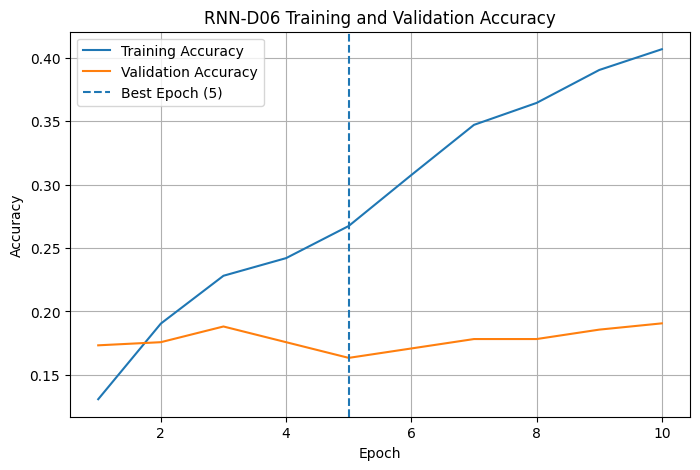

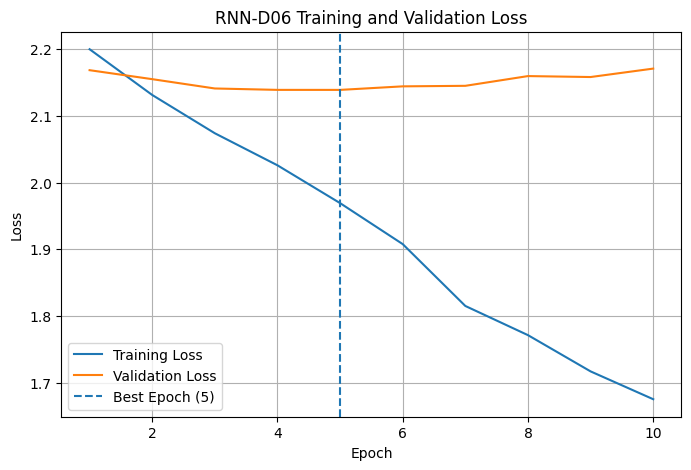

In [42]:
import matplotlib.pyplot as plt

epochs = range(
    1,
    len(history_D06.history["loss"]) + 1
)

# ---------------------------------------------------------
# Accuracy
# ---------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_D06.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history_D06.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.axvline(
    x=5,
    linestyle="--",
    label="Best Epoch (5)"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("RNN-D06 Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()


# ---------------------------------------------------------
# Loss
# ---------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_D06.history["loss"],
    label="Training Loss"
)

plt.plot(
    epochs,
    history_D06.history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    x=5,
    linestyle="--",
    label="Best Epoch (5)"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("RNN-D06 Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [43]:
from sklearn.metrics import classification_report

RNN_CLASSES = [
    "Rest",
    "Help",
    "Bathroom",
    "Pain",
    "Thanks",
    "Hunger",
    "No",
    "Thirst",
    "Yes"
]

print(
    classification_report(
        y_test_bands,
        d06_pred,
        target_names=RNN_CLASSES,
        digits=4
    )
)

              precision    recall  f1-score   support

        Rest     0.1538    0.1304    0.1412        46
        Help     0.1408    0.1961    0.1639        51
    Bathroom     0.1000    0.0541    0.0702        37
        Pain     0.1912    0.2653    0.2222        49
      Thanks     0.1087    0.1136    0.1111        44
      Hunger     0.1892    0.1591    0.1728        44
          No     0.2105    0.1667    0.1860        48
      Thirst     0.2000    0.2439    0.2198        41
         Yes     0.1389    0.1111    0.1235        45

    accuracy                         0.1630       405
   macro avg     0.1592    0.1600    0.1567       405
weighted avg     0.1605    0.1630    0.1588       405



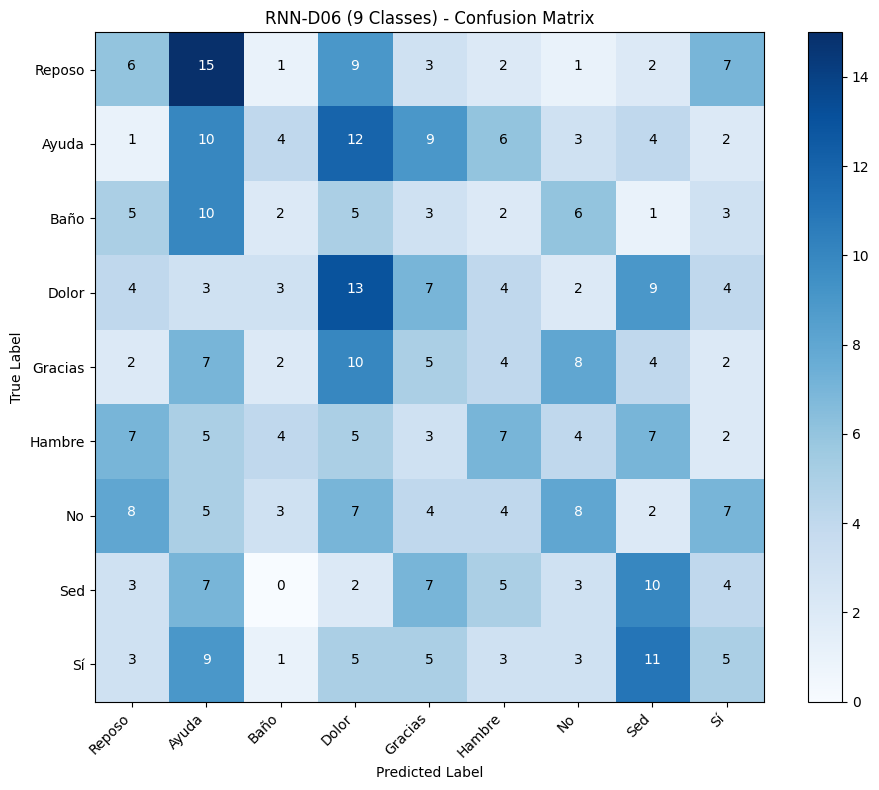

In [45]:
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

RNN_CLASSES_ES = [
    "Reposo",
    "Ayuda",
    "Baño",
    "Dolor",
    "Gracias",
    "Hambre",
    "No",
    "Sed",
    "Sí"
]

cm_d06 = confusion_matrix(
    y_test_bands,
    d06_pred
)

plt.figure(figsize=(10, 8))

plt.imshow(
    cm_d06,
    interpolation="nearest",
    cmap="Blues"
)

plt.title("RNN-D06 (9 Classes) - Confusion Matrix")
plt.colorbar()

ticks = np.arange(len(RNN_CLASSES_ES))

plt.xticks(
    ticks,
    RNN_CLASSES_ES,
    rotation=45,
    ha="right"
)

plt.yticks(
    ticks,
    RNN_CLASSES_ES
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

threshold = cm_d06.max() / 2

for i in range(cm_d06.shape[0]):
    for j in range(cm_d06.shape[1]):

        plt.text(
            j,
            i,
            f"{cm_d06[i, j]}",
            horizontalalignment="center",
            color="white"
            if cm_d06[i, j] > threshold
            else "black"
        )

plt.tight_layout()
plt.show()

In [46]:
# ---------------------------------------------------------
# RNN-D06 - Problematic Sequence Analysis
# ---------------------------------------------------------

misclassified_idx = np.where(
    d06_pred != y_test_bands
)[0]

problematic_sequences = []

for idx in misclassified_idx:

    true_class = int(y_test_bands[idx])
    predicted_class = int(d06_pred[idx])

    predicted_confidence = float(
        d06_prob[idx, predicted_class]
    )

    true_probability = float(
        d06_prob[idx, true_class]
    )

    problematic_sequences.append({
        "Test index": idx,
        "Clase real": RNN_CLASSES_ES[true_class],
        "Clase predicha": RNN_CLASSES_ES[predicted_class],
        "Confianza predicción": predicted_confidence,
        "Probabilidad clase real": true_probability
    })

problematic_df = pd.DataFrame(problematic_sequences)

problematic_df = (
    problematic_df
    .sort_values(
        by="Confianza predicción",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)

display(problematic_df)

,Test index,Clase real,Clase predicha,Confianza predicción,Probabilidad clase real
0,298,Dolor,Sed,0.439870,0.080548
1,7,No,Reposo,0.416941,0.201290
2,180,Dolor,Sed,0.406607,0.092824
3,75,Ayuda,Dolor,0.389668,0.089864
4,178,Baño,No,0.383103,0.086956
5,256,Sí,No,0.382187,0.098819
6,320,Reposo,Ayuda,0.381845,0.094935
7,152,Reposo,Ayuda,0.379331,0.062229
8,255,Gracias,Ayuda,0.369063,0.156513
9,141,Ayuda,Dolor,0.362662,0.079820


In [47]:
problematic_df.to_csv(
    os.path.join(
        RNN_RESULTS_DIR,
        "RNN_D06_problematic_sequences.csv"
    ),
    index=False
)

print("Problematic sequence analysis saved.")

Problematic sequence analysis saved.
